# 02 · Does a coupled detector really catch faults faster? A Monte Carlo check

**Claim under test** (from `docs/project_reference.md`). Two slices share resources, so their KPI noise is correlated with coefficient $\rho$. A CUSUM that uses *both* slices and knows the fault's shape $\delta$ should be faster than a CUSUM that watches only slice 1, by the information ratio

$$\text{gain} = \frac{\tfrac12\,\delta^\top\Sigma^{-1}\delta}{\tfrac12\,\delta_1^2} = \frac{\text{KL}_\text{coupled}}{\text{KL}_\text{single}}.$$

Notebook 01 showed that delay ≈ log(ARL)/KL only to first order, with an offset that depends on KL. So we expect the real speed-up at practical false-alarm rates to be **smaller** than this ratio. Here we measure it, for the four fault shapes in `docs/project_reference.md`, three correlations and two fault sizes. We also test what happens when the coupled detector **guesses the fault shape wrong**.

**Run it** from the project root (6 to 8 minutes). Tables and figures go to `results/02_coupled_gain/`.

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/02_coupled_gain.ipynb
```

**Sections:** 1 Setup · 2 The model and the two detectors · 3 Theory predictions · 4 Monte Carlo engine · 5 Equal-ARL calibration · 6 Measured gains · 7 Guessing the shape wrong · 8 Summary and exercises

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

SEED = 20261022
OUT = Path("../results/02_coupled_gain")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")                       # LaTeX write-up: figures, tables and key numbers go here
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)
(REPORT / "figures").mkdir(parents=True, exist_ok=True)
(REPORT / "tables").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png")                       # quick look
    fig.savefig(REPORT / "figures" / f"02_{name}.pdf")     # vector copy for the report

def save_tex_table(df, name, column_format):
    # tabular only; caption and label live in report/main.tex
    (REPORT / "tables" / f"02_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    # key results as \newcommand macros, so the report's prose updates when the notebook is re-run
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"02_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

def rng_for(*k):
    # independent, reproducible random stream labelled by the integers k
    return np.random.default_rng([SEED, 2, *k])

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 7, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

## 2. The model and the two detectors

**Data.** Each sample is a pair $x_n = (x_{1,n}, x_{2,n})$: the standardised KPI residuals of slice 1 and slice 2 (think: latency minus its normal level, divided by its normal standard deviation). In normal operation $x_n \sim \mathcal N(0, \Sigma)$ with $\Sigma = \begin{pmatrix}1 & \rho\\ \rho & 1\end{pmatrix}$, independent over time. After a fault the mean becomes $\delta = \delta_1 (1, s)$:

| shape | slice 2 shift $s$ | 5G reading (a guess, to be checked in the simulator) |
|---|---|---|
| (1, 0) | 0 | fault local to slice 1 |
| (1, ρ) | ρ | slice 2 moves exactly as its normal correlation predicts |
| (1, 1) | 1 | both slices shift equally, e.g. the shared pool slows down |
| (1, −ρ) | −ρ | slice 2 moves the opposite way, e.g. slice 1 grabs capacity from slice 2 |

**Detectors.** Both are CUSUMs, $W_n = \max(0, W_{n-1} + \ell(x_n))$, alarm when $W_n \ge h$. They differ only in the increment $\ell$:

- **Single-slice** (watches slice 1 only, knows $\delta_1$): $\ell = \delta_1 x_1 - \delta_1^2/2$, with $\text{KL}_\text{single} = \delta_1^2/2$.
- **Coupled** (knows $\delta$ and $\Sigma$): the full log-likelihood ratio $\ell = \delta^\top\Sigma^{-1}x - \tfrac12\delta^\top\Sigma^{-1}\delta$, with $\text{KL}_\text{coupled} = \tfrac12\delta^\top\Sigma^{-1}\delta$.

Signals link: $\delta^\top\Sigma^{-1}x = (L^{-1}\delta)^\top(L^{-1}x)$ with $\Sigma = LL^\top$. That is the textbook **matched filter in coloured noise**: whiten the data with $L^{-1}$, then correlate with the whitened signal. $\text{KL}_\text{coupled}$ is half the squared length of the fault *after whitening*.

The picture below shows why the shape matters. Normal noise at ρ = 0.9 is a thin cloud along the diagonal. A fault that points out of the cloud is easy to see; one that points along it hides in the noise.

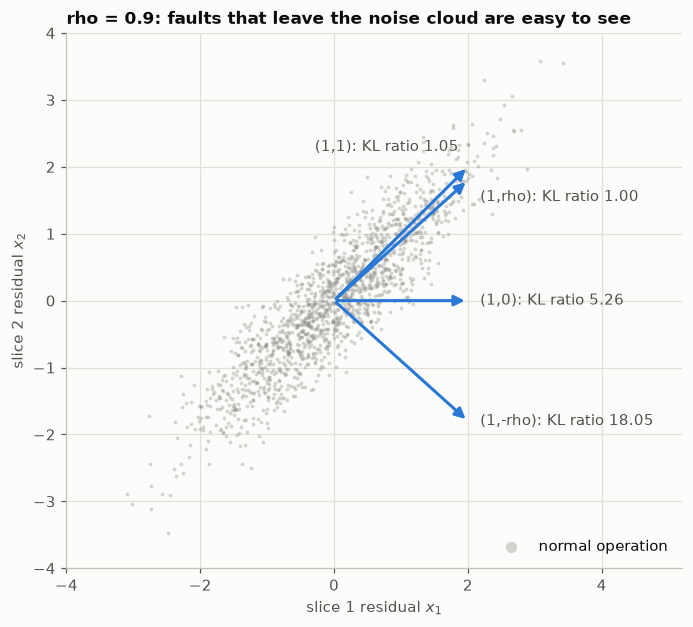

In [2]:
def sigma(rho):
    return np.array([[1.0, rho], [rho, 1.0]])

SHAPES = {"(1,0)": lambda r: (1.0, 0.0), "(1,rho)": lambda r: (1.0, r),
          "(1,1)": lambda r: (1.0, 1.0), "(1,-rho)": lambda r: (1.0, -r)}

def kl(shift, Sigma):
    d = np.asarray(shift, float)
    return 0.5 * d @ np.linalg.solve(Sigma, d)

rho, d1 = 0.9, 2.0
pts = rng_for(0).multivariate_normal([0, 0], sigma(rho), size=1500)
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.scatter(pts[:, 0], pts[:, 1], s=6, color=MUTED, alpha=0.35, linewidths=0, label="normal operation")
offsets = {"(1,0)": (8, 0, "left", "center"), "(1,rho)": (8, -6, "left", "top"),
           "(1,1)": (-6, 8, "right", "bottom"), "(1,-rho)": (8, 0, "left", "center")}
for name, s in SHAPES.items():
    v = d1 * np.array(s(rho))
    gain = kl(v, sigma(rho)) / (d1**2 / 2)
    ax.annotate("", v, (0, 0), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2, mutation_scale=14))
    dx, dy, ha, va = offsets[name]
    ax.annotate(f"{name}: KL ratio {gain:.2f}", v, xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, color=INK2)
ax.set_xlim(-4, 5.2); ax.set_ylim(-4, 4); ax.set_aspect("equal")
ax.set_xlabel("slice 1 residual $x_1$"); ax.set_ylabel("slice 2 residual $x_2$")
ax.set_title("rho = 0.9: faults that leave the noise cloud are easy to see")
ax.legend(loc="lower right", markerscale=3)
fig.tight_layout()
save_fig(fig, "fig1_geometry")
plt.show()

Two facts make the rest of the notebook simple.

1. **The coupled increment is just a univariate Gaussian.** With $a = \Sigma^{-1}\delta$ and $K = \text{KL}_\text{coupled}$, $\ell = a^\top x - K$ has variance $a^\top\Sigma a = 2K$, mean $-K$ before the fault and $+K$ after. So the coupled CUSUM behaves exactly like the notebook-01 CUSUM with an effective shift $\delta_\text{eff} = \sqrt{2K}$, and Siegmund's formula applies to it.
2. **For shape (1, ρ) the two detectors are identical.** $\Sigma^{-1}(1, \rho)^\top = (1, 0)^\top$, so the optimal statistic ignores slice 2 completely. Check:

In [3]:
def detector(assumed_shift, Sigma):
    '''CUSUM increment llr(x) = x @ a - c for an assumed post-fault mean vector d:
    a = Sigma^-1 d (whiten, then correlate), c = d . Sigma^-1 d / 2 (the KL of d).'''
    d = np.asarray(assumed_shift, float)
    a = np.linalg.solve(Sigma, d)
    return a, 0.5 * d @ a

a, c = detector((0.5, 0.9 * 0.5), sigma(0.9))
print(f"coupled detector for shape (1, rho), d1 = 0.5, rho = 0.9:  a = {np.round(a, 12)},  c = {c:.4f}")
print(f"single-slice detector:                                    a = [0.5 0. ],  c = {0.5**2 / 2:.4f}")

# fact 1, numerically: increment mean and variance before the fault, for shape (1,-rho)
S = sigma(0.9); a, c = detector((0.5, -0.45), S)
x = rng_for(1).multivariate_normal([0, 0], S, size=10**6)
inc = x @ a - c
print(f"shape (1,-rho): K = {c:.3f};  simulated increment mean {inc.mean():+.3f} (theory {-c:+.3f}), "
      f"variance {inc.var():.3f} (theory {2 * c:.3f})")

coupled detector for shape (1, rho), d1 = 0.5, rho = 0.9:  a = [0.5 0. ],  c = 0.1250
single-slice detector:                                    a = [0.5 0. ],  c = 0.1250


shape (1,-rho): K = 2.257;  simulated increment mean -2.254 (theory -2.257), variance 4.497 (theory 4.513)


## 3. Theory predictions

For each case we compute three numbers:

- **KL ratio**: the first-order gain claimed in `docs/project_reference.md`.
- **Siegmund-predicted gain at a given ARL**: pick each detector's threshold so that Siegmund's formula gives the target ARL, then take the ratio of Siegmund delays. Notebook 01 verified this formula for $\delta_\text{eff} = 0.5$ and 1; here some cases reach $\delta_\text{eff} \approx 4$, so we will see whether it still holds.
- **Measured gain** (section 6).

In [4]:
def siegmund_run_length(h, K, after_fault):
    # CUSUM with N(-K, 2K) increments before the fault and N(+K, 2K) after (delta_eff = sqrt(2K))
    de = np.sqrt(2 * K)
    b = h / de + 1.166
    D = de / 2 if after_fault else -de / 2
    return (np.exp(-2 * D * b) + 2 * D * b - 1) / (2 * D**2)

def h_for_arl(arl, K):
    # threshold whose Siegmund ARL equals `arl`
    f = lambda h: np.log(siegmund_run_length(h, K, False)) - np.log(arl)
    return brentq(f, 1e-6, 200) if f(1e-6) < 0 else 1e-6

def siegmund_gain(K_single, K_coupled, arl):
    d_s = siegmund_run_length(h_for_arl(arl, K_single), K_single, True)
    d_c = siegmund_run_length(h_for_arl(arl, K_coupled), K_coupled, True)
    return d_s / d_c

DELTA1 = [0.5, 1.0]
RHOS = [0.3, 0.6, 0.9]
TARGETS = [100, 1000, 10000]

rows = []
for d1 in DELTA1:
    for rho in RHOS:
        for name, s in SHAPES.items():
            Ks, Kc = d1**2 / 2, kl(d1 * np.array(s(rho)), sigma(rho))
            rows.append(dict(delta1=d1, rho=rho, shape=name, KL_ratio=Kc / Ks,
                             **{f"siegmund_gain_arl{t}": siegmund_gain(Ks, Kc, t) for t in TARGETS}))
theory = pd.DataFrame(rows)
theory.round(2)

,delta1,rho,shape,KL_ratio,siegmund_gain_arl100,siegmund_gain_arl1000,siegmund_gain_arl10000
0,0.5,0.3,"(1,0)",1.10,1.06,1.07,1.08
1,0.5,0.3,"(1,rho)",1.00,1.00,1.00,1.00
2,0.5,0.3,"(1,1)",1.54,1.30,1.39,1.44
3,0.5,0.3,"(1,-rho)",1.40,1.22,1.29,1.32
4,0.5,0.6,"(1,0)",1.56,1.31,1.41,1.46
5,0.5,0.6,"(1,rho)",1.00,1.00,1.00,1.00
6,0.5,0.6,"(1,1)",1.25,1.14,1.18,1.21
7,0.5,0.6,"(1,-rho)",3.25,2.12,2.51,2.73
8,0.5,0.9,"(1,0)",5.26,2.97,3.71,4.15
9,0.5,0.9,"(1,rho)",1.00,1.00,1.00,1.00


## 4. Monte Carlo engine

- All detectors run on the **same simulated data** (common random numbers), so differences between them are not just noise.
- Each run starts at $W = 0$. For the delay, the fault is present from the first sample: the worst case for CUSUM, as in notebook 01.
- Every detector has its own list of thresholds; one simulation records the first crossing of each.
- Runs stop when every detector has crossed its largest threshold, or after `max_steps` samples. A detector that has not alarmed by then gets `NaN` ("not detected").

In [5]:
def alarm_times(dets, thresholds, n_runs, rng, Sigma, shift=(0.0, 0.0), max_steps=None):
    '''First alarm times of several linear CUSUMs run on the same 2-slice data.

    dets: list of (a, c) with increment llr(x) = x @ a - c.
    thresholds: array (n_detectors, n_thresholds), each row ascending.
    Data: x_n ~ N(shift, Sigma), iid, n = 1, 2, ...
    Returns float array (n_runs, n_detectors, n_thresholds); NaN = no alarm within max_steps.
    '''
    A = np.stack([a for a, _ in dets], axis=1)              # (2, D)
    c = np.array([cc for _, cc in dets])                     # (D,)
    thr = np.asarray(thresholds, float)                      # (D, J)
    L = np.linalg.cholesky(Sigma)
    shift = np.asarray(shift, float)
    T = np.zeros((n_runs, *thr.shape), dtype=np.int64)
    runs = np.arange(n_runs)
    W = np.zeros((n_runs, len(dets)))
    step = 0
    while runs.size and (max_steps is None or step < max_steps):
        step += 1
        x = rng.standard_normal((runs.size, 2)) @ L.T + shift
        W = np.maximum(0.0, W + x @ A - c)
        new = (W[:, :, None] >= thr[None]) & (T[runs] == 0)
        if new.any():
            r, d, j = np.nonzero(new)
            T[runs[r], d, j] = step
        unfinished = (T[runs, :, -1] == 0).any(axis=1)
        runs, W = runs[unfinished], W[unfinished]
    return np.where(T > 0, T, np.nan)

def mean_ci(v):
    v = np.asarray(v, float)
    v = v[~np.isnan(v)]
    return v.mean(), 1.96 * v.std(ddof=1) / np.sqrt(v.size)

def ratio_ci(num, den, rng, n_boot=500):
    # 95% bootstrap interval for mean(num)/mean(den), resampling paired runs
    idx = rng.integers(0, len(num), size=(n_boot, len(num)))
    r = np.nanmean(num[idx], axis=1) / np.nanmean(den[idx], axis=1)
    return np.quantile(r, [0.025, 0.975])

## 5. Equal-ARL calibration

A fair comparison needs both detectors to raise false alarms equally often. For each $(\delta_1, \rho)$:

1. Put every detector on a grid of thresholds whose Siegmund ARL runs from about $10^{1.25}$ to $10^{4.5}$ (Siegmund is only used to *place* the grid).
2. Measure the actual ARL at each grid point by Monte Carlo (no fault, 2,000 runs).
3. Interpolate log(ARL) against $h$ to find the threshold $h^*$ that gives each target ARL: $10^2, 10^3, 10^4$.

Four detectors are calibrated together: single-slice, plus the coupled detector for shapes (1, 0), (1, 1) and (1, −ρ). The coupled detector for (1, ρ) is the single-slice detector, as shown above.

This is the slow cell (about 4 minutes).

In [6]:
DET_NAMES = ["single", "coupled (1,0)", "coupled (1,1)", "coupled (1,-rho)"]
MATCHED = {"(1,0)": "coupled (1,0)", "(1,rho)": "single", "(1,1)": "coupled (1,1)", "(1,-rho)": "coupled (1,-rho)"}
LOG10_GRID = np.arange(1.25, 4.51, 0.25)
R_ARL, R_DELAY, MAX_STEPS = 2000, 5000, 20000

def make_detectors(d1, rho):
    S = sigma(rho)
    return [(np.array([d1, 0.0]), d1**2 / 2),           # single: slice 1 only
            detector((d1, 0.0), S), detector((d1, d1), S), detector((d1, -rho * d1), S)]

cal_rows, h_star = [], {}
for i, d1 in enumerate(DELTA1):
    for k, rho in enumerate(RHOS):
        dets = make_detectors(d1, rho)
        grid = np.array([[h_for_arl(10**g, c) for g in LOG10_GRID] for _, c in dets])
        T0 = alarm_times(dets, grid, R_ARL, rng_for(10, i, k), sigma(rho))
        arl = np.nanmean(T0, axis=0)
        assert np.isnan(T0).sum() == 0
        assert (arl[:, 0] < min(TARGETS)).all() and (arl[:, -1] > max(TARGETS)).all(), "grid must bracket targets"
        for m, name in enumerate(DET_NAMES):
            for j in range(grid.shape[1]):
                cal_rows.append(dict(delta1=d1, rho=rho, detector=name, K=dets[m][1], h=grid[m, j], arl_mc=arl[m, j],
                                     arl_siegmund=siegmund_run_length(grid[m, j], dets[m][1], False)))
        h_star[d1, rho] = np.array([[np.interp(np.log(t), np.log(arl[m]), grid[m]) for t in TARGETS]
                                    for m in range(len(dets))])
cal = pd.DataFrame(cal_rows)
cal.to_csv(OUT / "arl_calibration.csv", index=False)

err = 100 * (cal.arl_siegmund / cal.arl_mc - 1)
print(f"Siegmund ARL vs Monte Carlo over all {len(cal)} grid points: median |error| {err.abs().median():.1f}%, "
      f"max |error| {err.abs().max():.1f}%")
print(cal.assign(abs_err_pct=err.abs()).groupby("detector").abs_err_pct.max().round(1).to_string())

Siegmund ARL vs Monte Carlo over all 336 grid points: median |error| 1.8%, max |error| 71.8%


detector
coupled (1,-rho)    71.8
coupled (1,0)       14.5
coupled (1,1)        7.9
single               5.2


## 6. Measured gains

For each fault shape, simulate 5,000 runs with the fault present from the first sample, run all four detectors at their calibrated thresholds, and compare delays at the same ARL. The **measured gain** is (single-slice delay) / (matched coupled delay). Its 95% interval is a bootstrap over the paired runs.

In [7]:
delay_rows, gain_rows, raw = [], [], {}
for i, d1 in enumerate(DELTA1):
    for k, rho in enumerate(RHOS):
        dets = make_detectors(d1, rho)
        for s_i, (shape, s) in enumerate(SHAPES.items()):
            shift = d1 * np.array(s(rho))
            T1 = alarm_times(dets, h_star[d1, rho], R_DELAY, rng_for(20, i, k, s_i), sigma(rho),
                             shift=shift, max_steps=MAX_STEPS)
            raw[d1, rho, shape] = T1
            for m, name in enumerate(DET_NAMES):
                for j, t in enumerate(TARGETS):
                    mu, ci = mean_ci(T1[:, m, j])
                    delay_rows.append(dict(delta1=d1, rho=rho, shape=shape, detector=name, arl=t,
                                           delay=mu, delay_ci=ci, not_detected=np.isnan(T1[:, m, j]).mean()))
            ms = DET_NAMES.index(MATCHED[shape])
            Ks, Kc = d1**2 / 2, kl(shift, sigma(rho))
            for j, t in enumerate(TARGETS):
                lo, hi = ratio_ci(T1[:, 0, j], T1[:, ms, j], rng_for(30, i, k, s_i, j))
                gain_rows.append(dict(delta1=d1, rho=rho, shape=shape, arl=t, KL_ratio=Kc / Ks,
                                      siegmund_gain=siegmund_gain(Ks, Kc, t),
                                      measured_gain=np.nanmean(T1[:, 0, j]) / np.nanmean(T1[:, ms, j]),
                                      gain_lo=lo, gain_hi=hi,
                                      delay_single=np.nanmean(T1[:, 0, j]), delay_coupled=np.nanmean(T1[:, ms, j])))
delays = pd.DataFrame(delay_rows); delays.to_csv(OUT / "delays.csv", index=False)
gains = pd.DataFrame(gain_rows); gains.to_csv(OUT / "gains.csv", index=False)

table = gains[gains.arl == 1000][["delta1", "rho", "shape", "KL_ratio", "siegmund_gain", "measured_gain",
                                  "gain_lo", "gain_hi", "delay_single", "delay_coupled"]]
print("Gain at ARL = 1000 (worst-case delays in samples)")
table.round(2)

Gain at ARL = 1000 (worst-case delays in samples)


,delta1,rho,shape,KL_ratio,siegmund_gain,measured_gain,gain_lo,gain_hi,delay_single,delay_coupled
1,0.5,0.3,"(1,0)",1.10,1.07,1.07,1.07,1.08,30.66,28.54
4,0.5,0.3,"(1,rho)",1.00,1.00,1.00,1.00,1.00,30.68,30.68
7,0.5,0.3,"(1,1)",1.54,1.39,1.38,1.36,1.40,30.97,22.41
10,0.5,0.3,"(1,-rho)",1.40,1.29,1.28,1.27,1.30,30.94,24.11
13,0.5,0.6,"(1,0)",1.56,1.41,1.41,1.39,1.43,31.34,22.29
16,0.5,0.6,"(1,rho)",1.00,1.00,1.00,1.00,1.00,31.21,31.21
19,0.5,0.6,"(1,1)",1.25,1.18,1.18,1.17,1.20,31.30,26.42
22,0.5,0.6,"(1,-rho)",3.25,2.51,2.53,2.48,2.57,31.41,12.43
25,0.5,0.9,"(1,0)",5.26,3.71,3.75,3.69,3.83,31.01,8.26
28,0.5,0.9,"(1,rho)",1.00,1.00,1.00,1.00,1.00,31.03,31.03


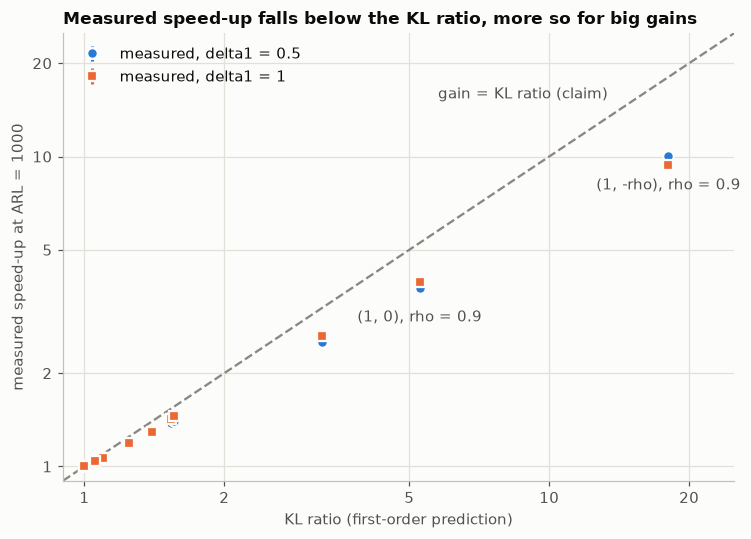

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
lim = [0.9, 25]
ax.plot(lim, lim, color=MUTED, ls="--", lw=1.5)
ax.annotate("gain = KL ratio (claim)", (14, 14), xytext=(-6, 6), textcoords="offset points",
            ha="right", va="bottom", color=INK2, rotation=0)
for d1, col, mk in [(0.5, BLUE, "o"), (1.0, ORANGE, "s")]:
    g = gains[(gains.arl == 1000) & (gains.delta1 == d1)]
    ax.errorbar(g.KL_ratio, g.measured_gain, yerr=[g.measured_gain - g.gain_lo, g.gain_hi - g.measured_gain],
                fmt=mk, color=col, mec=SURFACE, mew=1.5, capsize=0, label=f"measured, delta1 = {d1:g}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ticks = [1, 2, 5, 10, 20]
ax.set_xticks(ticks, [str(t) for t in ticks]); ax.set_yticks(ticks, [str(t) for t in ticks])
ax.minorticks_off()
for shape, label in [("(1,0)", "(1, 0), rho = 0.9"), ("(1,-rho)", "(1, -rho), rho = 0.9")]:
    g = gains[(gains.arl == 1000) & (gains.delta1 == 0.5) & (gains.rho == 0.9) & (gains["shape"] == shape)].iloc[0]
    ax.annotate(label, (g.KL_ratio, g.measured_gain), xytext=(0, -14), textcoords="offset points",
                ha="center", va="top", color=INK2)
ax.set_xlabel("KL ratio (first-order prediction)")
ax.set_ylabel("measured speed-up at ARL = 1000")
ax.set_title("Measured speed-up falls below the KL ratio, more so for big gains")
ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "fig2_gain_vs_kl")
plt.show()

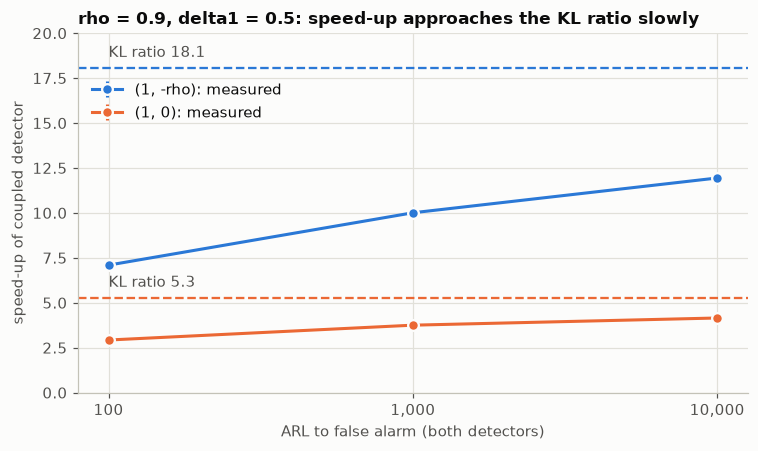

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for shape, col, lab in [("(1,-rho)", BLUE, "(1, -rho)"), ("(1,0)", ORANGE, "(1, 0)")]:
    g = gains[(gains.delta1 == 0.5) & (gains.rho == 0.9) & (gains["shape"] == shape)]
    ax.errorbar(g.arl, g.measured_gain, yerr=[g.measured_gain - g.gain_lo, g.gain_hi - g.measured_gain],
                fmt="o-", color=col, mec=SURFACE, mew=1.5, capsize=0, label=f"{lab}: measured")
    ax.axhline(g.KL_ratio.iloc[0], color=col, ls="--", lw=1.5)
    ax.annotate(f"KL ratio {g.KL_ratio.iloc[0]:.1f}", (g.arl.iloc[0], g.KL_ratio.iloc[0]), xytext=(0, 5),
                textcoords="offset points", ha="left", va="bottom", color=INK2)
ax.set_xscale("log")
ax.set_xticks(TARGETS, ["100", "1,000", "10,000"]); ax.minorticks_off()
ax.set_ylim(0, 20)
ax.set_xlabel("ARL to false alarm (both detectors)")
ax.set_ylabel("speed-up of coupled detector")
ax.set_title("rho = 0.9, delta1 = 0.5: speed-up approaches the KL ratio slowly")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9))
fig.tight_layout()
save_fig(fig, "fig3_gain_vs_arl")
plt.show()

**What the simulation shows**

- **Shape (1, ρ): no gain at all.** The two detectors are the same detector, so the ratio is exactly 1.
- **For the other shapes the speed-up is real but smaller than the KL ratio, and the shortfall grows with the size of the gain.** At ARL 1000 and ρ = 0.9: for a fault local to slice 1 the KL ratio is 5.26, and the measured speed-up is 3.75 (δ₁ = 0.5) and 3.92 (δ₁ = 1). When slice 2 moves the opposite way, the KL ratio is 18.05 and the measured speed-up is 10.0 and 9.4. For small gains (ρ = 0.3) the two nearly agree (1.07 vs 1.10).
- **The speed-up grows with the ARL, but slowly.** At ARL 10⁴ the two ρ = 0.9 cases reach 4.15 and 11.9 (δ₁ = 0.5), still well short of 5.26 and 18.05.
- **Siegmund-based predictions** (column `siegmund_gain`) agree with the measured gain to within about 2% in 16 of the 18 cases with a real gain. They overpredict by 4% and 24% for shape (1, −ρ) at ρ = 0.9 (δ_eff ≈ 2.1 and 4.25). The calibration cell shows why: for the strongest detector, Siegmund's ARL is off by up to 72%. The approximation is built for small shifts; for large ones, thresholds must come from simulation.

## 7. Guessing the shape wrong

A real system does not know the fault shape in advance. Suppose it uses the coupled detector tuned for the most "useful-looking" case, a fault local to slice 1, shape (1, 0). This is the regression-adjusted CUSUM of statistical process control: it watches slice 1 *after subtracting what slice 2 predicts*, $x_1 - \rho x_2$. What happens when the real fault has another shape?

**Prediction.** A CUSUM tuned for $\delta_a$ but facing a true shift $\delta$ drifts upward at $\delta_a^\top\Sigma^{-1}\delta - \tfrac12\delta_a^\top\Sigma^{-1}\delta_a$ per sample. For $\delta_a = \delta_1(1, 0)$ and $\delta = \delta_1(1, s)$ this is

$$\text{drift} = \delta_1^2\,\frac{\tfrac12 - \rho s}{1-\rho^2}.$$

If $\rho s \ge \tfrac12$ the drift is zero or negative, so after the fault the detector behaves as if nothing happened. It only alarms through a random noise excursion, like a false alarm. That covers shape (1, 1) for every $\rho \ge 0.5$, and shape (1, ρ) for every $\rho \ge 0.71$. This is the same "halfway" rule as the $\delta/2$ decision boundary in notebook 01, measured in whitened units.

In [10]:
mm_rows = []
for d1 in DELTA1:
    for rho in RHOS:
        for shape, s in SHAPES.items():
            T1 = raw[d1, rho, shape]
            j = TARGETS.index(1000)
            single, tuned = T1[:, 0, j], T1[:, DET_NAMES.index("coupled (1,0)"), j]
            sv = s(rho)[1]
            mm_rows.append(dict(delta1=d1, rho=rho, shape=shape,
                                drift_theory=d1**2 * (0.5 - rho * sv) / (1 - rho**2),
                                delay_single=np.nanmean(single), delay_tuned_10=np.nanmean(tuned),
                                slowdown=np.nanmean(tuned) / np.nanmean(single),
                                not_detected=np.isnan(tuned).mean()))
mm = pd.DataFrame(mm_rows)
mm.to_csv(OUT / "wrong_shape.csv", index=False)
print("Coupled detector tuned for (1,0), at ARL = 1000. slowdown = its delay / single-slice delay")
mm.round(2)

Coupled detector tuned for (1,0), at ARL = 1000. slowdown = its delay / single-slice delay


,delta1,rho,shape,drift_theory,delay_single,delay_tuned_10,slowdown,not_detected
0,0.5,0.3,"(1,0)",0.14,30.66,28.54,0.93,0.0
1,0.5,0.3,"(1,rho)",0.11,30.68,33.28,1.08,0.0
2,0.5,0.3,"(1,1)",0.05,30.97,51.46,1.66,0.0
3,0.5,0.3,"(1,-rho)",0.16,30.94,25.39,0.82,0.0
4,0.5,0.6,"(1,0)",0.20,31.34,22.29,0.71,0.0
5,0.5,0.6,"(1,rho)",0.05,31.21,46.60,1.49,0.0
6,0.5,0.6,"(1,1)",-0.04,31.30,108.82,3.48,0.0
7,0.5,0.6,"(1,-rho)",0.34,31.41,14.30,0.46,0.0
8,0.5,0.9,"(1,0)",0.66,31.01,8.26,0.27,0.0
9,0.5,0.9,"(1,rho)",-0.41,31.03,197.51,6.37,0.0


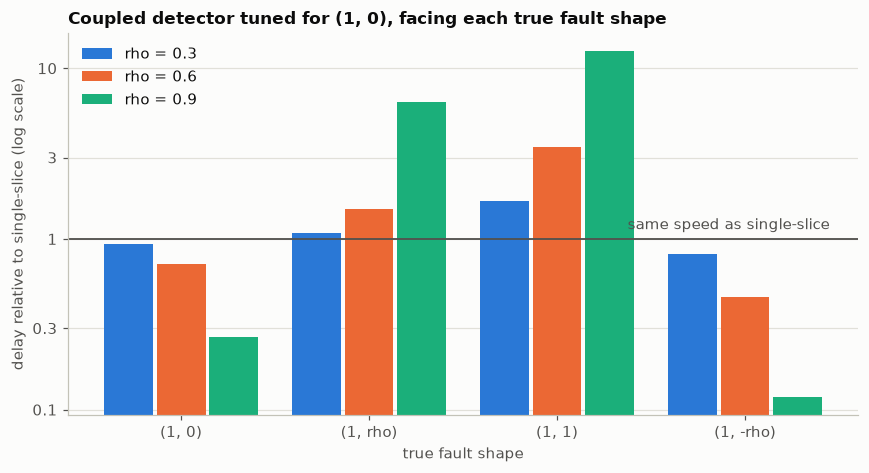

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.4))
g = mm[mm.delta1 == 0.5]
shape_order = list(SHAPES)
xs = np.arange(len(shape_order))
w = 0.26
for r_i, (rho, col) in enumerate(zip(RHOS, [BLUE, ORANGE, AQUA])):
    v = g[g.rho == rho].set_index("shape").loc[shape_order, "slowdown"]
    ax.bar(xs + (r_i - 1) * (w + 0.02), v, width=w, color=col, label=f"rho = {rho:g}")
ax.axhline(1, color=INK2, lw=1.2)
ax.annotate("same speed as single-slice", (xs[-1] + 0.45, 1), xytext=(0, 4), textcoords="offset points",
            ha="right", va="bottom", color=INK2)
ax.set_yscale("log")
ax.set_yticks([0.1, 0.3, 1, 3, 10], ["0.1", "0.3", "1", "3", "10"]); ax.minorticks_off()
ax.set_xticks(xs, ["(1, 0)", "(1, rho)", "(1, 1)", "(1, -rho)"])
ax.grid(axis="x", visible=False)
ax.set_xlabel("true fault shape")
ax.set_ylabel("delay relative to single-slice (log scale)")
ax.set_title("Coupled detector tuned for (1, 0), facing each true fault shape")
ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "fig4_wrong_shape")
plt.show()

**What the simulation shows**

- **The drift formula predicts the behaviour.** Where the predicted post-fault drift is negative (shape (1, 1) at ρ = 0.6 and 0.9; shape (1, ρ) at ρ = 0.9), the tuned detector is very slow. At ρ = 0.9 and δ₁ = 0.5 it needs about 389 samples when both slices shift equally, against 31 for the plain single-slice CUSUM (12.7× slower). It is 6.4× slower when slice 2 follows its normal correlation. With δ₁ = 1 the equal-shift case is 32× slower.
- **Even a small positive drift costs a lot.** At ρ = 0.3 the equal-shift fault still takes 1.7× longer than with the single-slice CUSUM.
- **When the guess is right or close, the gain is large:** 3.8× faster on (1, 0) and 8.5× faster on (1, −ρ) at ρ = 0.9 (δ₁ = 0.5).
- **Lesson.** Exploiting the correlation means betting on a fault shape. The shapes this detector loses on are the "shared" ones, such as a slowdown of the common pool, which may well be the most common slicing fault. A practical detector has to cover several shapes (a bank of CUSUMs, or a GLR-CUSUM), and the price of that robustness is the next thing to measure.

In [12]:
# Export tables and key numbers for report/main.tex (figures were exported as they were drawn)
SHAPE_TEX = {"(1,0)": "$(1,0)$", "(1,rho)": r"$(1,\rho)$", "(1,1)": "$(1,1)$", "(1,-rho)": r"$(1,-\rho)$"}
g = gains[gains.arl == 1000]
tab = pd.DataFrame({
    r"$\delta_1$": g.delta1.map("{:g}".format), r"$\rho$": g.rho.map("{:g}".format),
    "shape": g["shape"].map(SHAPE_TEX),
    "KL ratio": g.KL_ratio.map("{:.2f}".format),
    "Siegmund": g.siegmund_gain.map("{:.2f}".format),
    "measured [95\\% CI]": [f"{m:.2f} [{lo:.2f}, {hi:.2f}]" for m, lo, hi in zip(g.measured_gain, g.gain_lo, g.gain_hi)],
    "delay, single": g.delay_single.map("{:.1f}".format),
    "delay, coupled": g.delay_coupled.map("{:.1f}".format),
})
save_tex_table(tab, "gains_arl1000", "rrlrrlrr")

tab = pd.DataFrame({
    r"$\delta_1$": mm.delta1.map("{:g}".format), r"$\rho$": mm.rho.map("{:g}".format),
    "true shape": mm["shape"].map(SHAPE_TEX),
    "drift after fault": mm.drift_theory.map("{:+.3f}".format),
    "delay, single": mm.delay_single.map("{:.1f}".format),
    r"delay, tuned $(1,0)$": mm.delay_tuned_10.map("{:.1f}".format),
    "slowdown": mm.slowdown.map("{:.2f}".format),
})
save_tex_table(tab, "wrong_shape", "rrlrrrr")

def pick(df, **kw):
    for k, v in kw.items():
        df = df[df[k] == v]
    return df.iloc[0]

err = (100 * (cal.arl_siegmund / cal.arl_mc - 1)).abs()
big = (cal.delta1 == 1.0) & (cal.rho == 0.9) & (cal.detector == "coupled (1,-rho)")
G = lambda **kw: pick(gains[gains.arl == 1000], **kw)
M = lambda **kw: pick(mm, **kw)
save_tex_numbers({
    "SiegErrSmall": f"{err[cal.K <= 0.5].max():.0f}",
    "SiegErrLargeK": f"{err[big].max():.0f}",
    "KLLocalNine": f"{G(delta1=0.5, rho=0.9, shape='(1,0)').KL_ratio:.2f}",
    "GainLocalNine": f"{G(delta1=0.5, rho=0.9, shape='(1,0)').measured_gain:.2f}",
    "GainLocalNineOne": f"{G(delta1=1.0, rho=0.9, shape='(1,0)').measured_gain:.2f}",
    "KLOppNine": f"{G(delta1=0.5, rho=0.9, shape='(1,-rho)').KL_ratio:.2f}",
    "GainOppNine": f"{G(delta1=0.5, rho=0.9, shape='(1,-rho)').measured_gain:.2f}",
    "GainOppNineOne": f"{G(delta1=1.0, rho=0.9, shape='(1,-rho)').measured_gain:.2f}",
    "SlowEqualNine": f"{M(delta1=0.5, rho=0.9, shape='(1,1)').slowdown:.1f}",
    "DelayEqualNineTuned": f"{M(delta1=0.5, rho=0.9, shape='(1,1)').delay_tuned_10:.0f}",
    "DelayEqualNineSingle": f"{M(delta1=0.5, rho=0.9, shape='(1,1)').delay_single:.0f}",
    "SlowEqualSix": f"{M(delta1=0.5, rho=0.6, shape='(1,1)').slowdown:.1f}",
    "SlowFollowNine": f"{M(delta1=0.5, rho=0.9, shape='(1,rho)').slowdown:.1f}",
    "SpeedLocalNine": f"{1 / M(delta1=0.5, rho=0.9, shape='(1,0)').slowdown:.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("02_*")))

exported: ['02_gains_arl1000.tex', '02_numbers.tex', '02_wrong_shape.tex']


## 8. Summary

- **The coupled detector's advantage depends on the fault's direction relative to the noise correlation.** There is none when slice 2 moves as its normal correlation predicts, and a large one when the fault breaks the coupling.
- **At practical false-alarm rates the speed-up is well below the KL ratio:** 3.75× instead of 5.26×, and 10× instead of 18× (ρ = 0.9, ARL 1000). It approaches the KL ratio only slowly as the ARL grows, as notebook 01's offset formula predicted.
- **Siegmund's approximation predicts the speed-up well for moderate shifts, but fails for δ_eff ≈ 4.** Thresholds for strong detectors must come from simulation.
- **A coupled detector tuned to the wrong shape can be an order of magnitude slower than the simple single-slice CUSUM.** It is effectively blind when ρs ≥ ½.
- **For the project:** measure Σ and the fault signatures in the simulator rather than assuming them; use a detector that is robust to an unknown shape; always compare detectors at a common, simulated ARL.

### Try it yourself
1. **A bank of detectors.** Run the single-slice CUSUM and the three coupled ones together and alarm on the first to fire. Recalibrate one common threshold so the bank's ARL is 1000. How much of each matched gain survives, and is any shape still missed?
2. **Unknown Σ.** Estimate ρ from 500 fault-free samples and plug the estimate into the coupled detector. How far does the real ARL move from the target?
3. **A fairer per-slice baseline.** Add a CUSUM on slice 2 and alarm if either per-slice CUSUM fires (recalibrated to ARL 1000). How do the gains change for shapes (1, 1) and (1, −ρ), where slice 2 also moves?